# Superposition Models

**The superposition models calculate the effective wind speed given the local wind speed and deficits (typically from multiple sources)**

There are four different superposition models in PyWake:

- [LinearSum](#LinearSum): Deficits sum up linearly.
- [SquaredSum](#SquaredSum): Deficits sum as root-sum-square.
- [MaxSum](#MaxSum): Only the largest deficit is considered.
- [SqrMaxSum](#SqrMaxSum): The root-sum-square of the local turbulence intensity and the maximum value of the added turbulence caused by the source turbine is considered.

**Install PyWake if needed**

In [1]:
# Install PyWake if needed
try:
    import py_wake
except ModuleNotFoundError:
    !pip install git+https://gitlab.windenergy.dtu.dk/TOPFARM/PyWake.git

In [4]:
import numpy as np
import matplotlib.pyplot as plt

from py_wake import BastankhahGaussian
from py_wake.examples.data.hornsrev1 import V80, Hornsrev1Site

site = Hornsrev1Site()
windTurbines = V80()

### LinearSum

In general, LinearSum should be used in combination with `use_effective_ws=True` which makes downstream wind turbines feel the effective wind speed (including wake effects from upstream turbines) instead of the ambient free-stream wind speed. Otherwise negative wind speeds may occur.

Text(0, 0.5, 'y [m]')

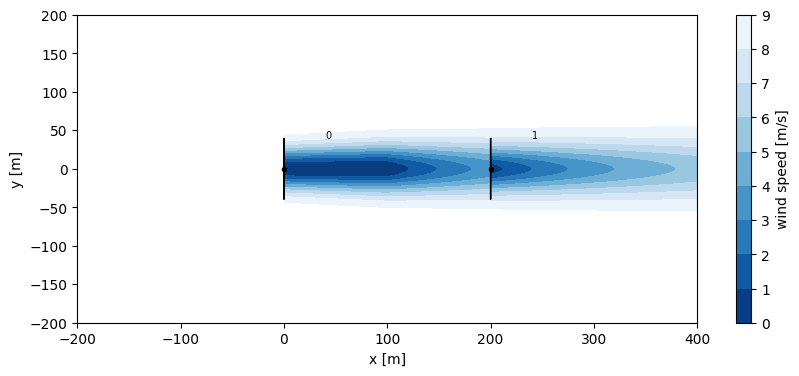

In [5]:
from py_wake.superposition_models import LinearSum

linear_sum = BastankhahGaussian(site, windTurbines, superpositionModel=LinearSum(), use_effective_ws=True)
plt.figure(figsize=(10,4))
linear_sum([0,200],[0,0],wd=270,ws=10).flow_map().plot_wake_map(levels=np.arange(0,10))
plt.xlabel('x [m]')
plt.ylabel('y [m]')

### SquaredSum

The SquaredSum model is often used in combination with wake deficit models where the downstream wakes are scaled with the ambient free-stream velocity to avoid negative wind speeds. It is, however, a method to compensate for an inconsistent formulation, see section 2.2 in https://backend.orbit.dtu.dk/ws/portalfiles/portal/151671395/Park2_Documentation_and_Validation.pdf

Text(0, 0.5, 'y [m]')

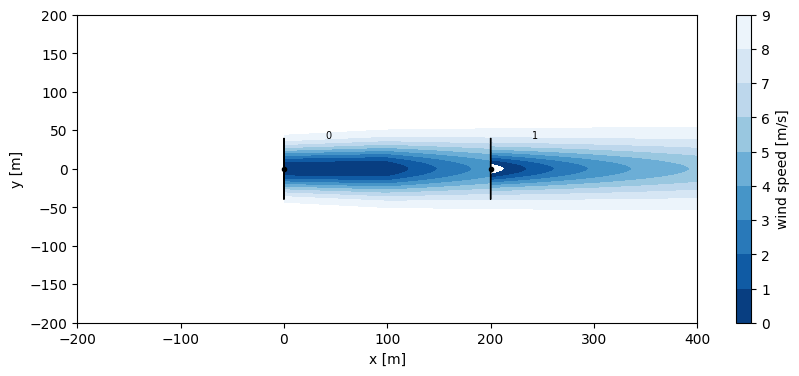

In [6]:
from py_wake.superposition_models import SquaredSum

squared_sum = BastankhahGaussian(site, windTurbines, superpositionModel=SquaredSum())
plt.figure(figsize=(10,4))
squared_sum([0,200],[0,0],wd=270,ws=10).flow_map().plot_wake_map(levels=np.arange(0,10))
plt.xlabel('x [m]')
plt.ylabel('y [m]')

### MaxSum

Text(0, 0.5, 'y [m]')

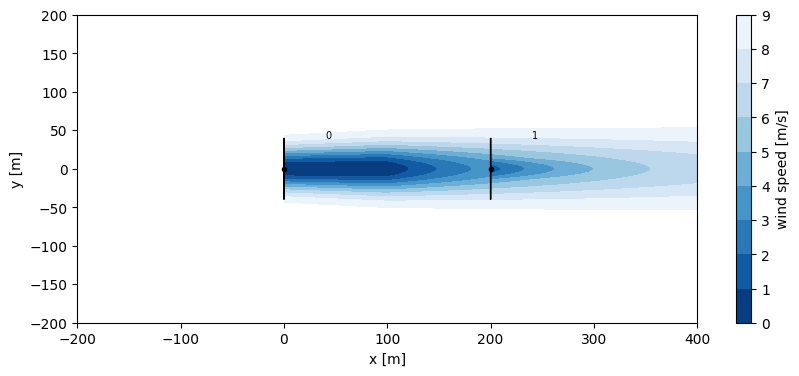

In [7]:
from py_wake.superposition_models import MaxSum

max_sum = BastankhahGaussian(site, windTurbines, superpositionModel=MaxSum())
plt.figure(figsize=(10,4))
max_sum([0,200],[0,0],wd=270,ws=10).flow_map().plot_wake_map(levels=np.arange(0,10))
plt.xlabel('x [m]')
plt.ylabel('y [m]')

### SqrMaxSum

Text(0, 0.5, 'y [m]')

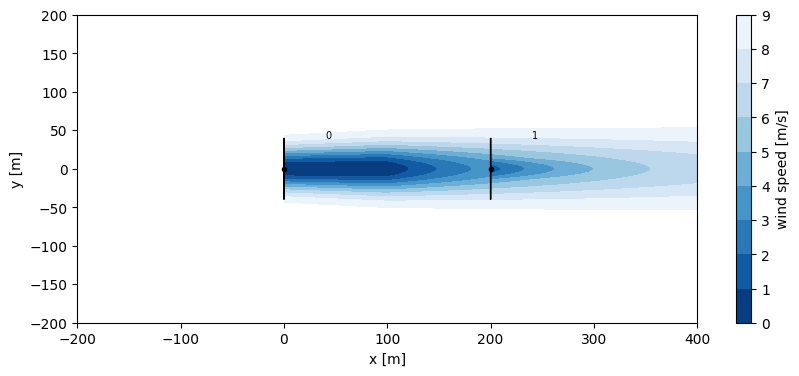

In [8]:
from py_wake.superposition_models import SqrMaxSum

max_sum = BastankhahGaussian(site, windTurbines, superpositionModel=MaxSum())
plt.figure(figsize=(10,4))
max_sum([0,200],[0,0],wd=270,ws=10).flow_map().plot_wake_map(levels=np.arange(0,10))
plt.xlabel('x [m]')
plt.ylabel('y [m]')